# Régressions du salaire selon le sexe, l’âge, la CSP et le secteur

On étudie les associations entre le salaire net moyen mensuel, le sexe, la tranche d’âge, la catégorie socio-professionnelle (CSP) et le secteur d’activité. L’analyse porte sur les données du secteur privé, en euros constants.

Les modèles incluent des effets fixes par année lorsque la comparaison porte sur plusieurs groupes, et regroupent les erreurs-types par année. Après les analyses par âge et par CSP, les sections 9 à 11 étudient successivement l’évolution de l’écart femmes-hommes dans le temps, ses variations selon la CSP, puis selon les quantiles de salaire. Les observations sont des **moyennes ou quantiles agrégés par groupe** : les résultats décrivent des associations, pas des effets causaux individuels.

## 1. Chargement et préparation des données

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf


def formater_p_value(valeur):
    if valeur < 0.001:
        return '< 0,001'
    return f'{valeur:.3f}'.replace('.', ',')


def trouver_racine_projet():
    courant = Path.cwd().resolve()
    for dossier in (courant, *courant.parents):
        if (dossier / 'Data nettoyees').is_dir():
            return dossier
    raise FileNotFoundError(
        'Dossier « Data nettoyees » introuvable. '
        'Lancez ce notebook depuis le projet ou un de ses sous-dossiers.'
    )


RACINE = trouver_racine_projet()
CHEMIN_DONNEES = (
    RACINE
    / 'Data nettoyees'
    / 'DS_DERA_PRIVE_SERIES_LONGUES_data_nettoye.csv'
)
if not CHEMIN_DONNEES.is_file():
    raise FileNotFoundError(
        f'Fichier de données nettoyées absent : {CHEMIN_DONNEES}. '
        'Lancez d’abord Nettoyage_donnees.ipynb.'
    )

prive = pd.read_csv(CHEMIN_DONNEES, sep=';', encoding='utf-8-sig')
print(f'Fichier chargé : {CHEMIN_DONNEES.name} ({len(prive):,} lignes)')
print(f'Colonnes disponibles : {", ".join(prive.columns)}')

Fichier chargé : DS_DERA_PRIVE_SERIES_LONGUES_data_nettoye.csv (14,768 lignes)
Colonnes disponibles : geo, zone_geo, frequence, secteur_activite, tranche_age, taille_entreprise, categorie_socio_prof, sexe, temps_travail, centile_salaire, indicateur, unite, annee, valeur


## 2. Construction de l’échantillon

On conserve le salaire net moyen mensuel, pour la France et l’ensemble des secteurs, âges, tailles d’entreprise et temps de travail. On écarte les modalités « Ensemble » du sexe et de la CSP afin de comparer les femmes et les hommes dans chacune des CSP.

In [2]:
SALAIRE = 'Salaire net moyen mensuel (Euros constants)'
colonnes_requises = {
    'indicateur', 'centile_salaire', 'geo', 'secteur_activite',
    'tranche_age', 'taille_entreprise', 'temps_travail',
    'categorie_socio_prof', 'sexe', 'annee', 'valeur',
}
colonnes_absentes = colonnes_requises.difference(prive.columns)
if colonnes_absentes:
    raise ValueError(f'Colonnes manquantes dans le fichier : {sorted(colonnes_absentes)}')

echantillon = prive.loc[
    prive['indicateur'].eq(SALAIRE)
    & prive['centile_salaire'].eq('Ensemble')
    & prive['geo'].eq('F')
    & prive['secteur_activite'].eq('Ensemble des secteurs')
    & prive['tranche_age'].eq('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
    & prive['sexe'].isin(['Femme', 'Homme'])
    & prive['categorie_socio_prof'].ne('Ensemble'),
    ['annee', 'sexe', 'categorie_socio_prof', 'valeur'],
].copy()

echantillon['annee'] = pd.to_numeric(echantillon['annee'], errors='coerce')
echantillon['valeur'] = pd.to_numeric(echantillon['valeur'], errors='coerce')
if echantillon[['annee', 'valeur']].isna().any().any():
    raise ValueError('Des années ou des salaires sont manquants ou non numériques dans l’échantillon.')
echantillon['annee'] = echantillon['annee'].astype(int)
echantillon['femme'] = echantillon['sexe'].eq('Femme').astype(int)

cles = ['annee', 'sexe', 'categorie_socio_prof']
if echantillon.duplicated(cles).any():
    raise ValueError(f'Plusieurs observations pour les mêmes clés : {cles}')

annees = sorted(echantillon['annee'].unique())
sexes = ['Femme', 'Homme']
csp = sorted(echantillon['categorie_socio_prof'].unique())
attendues = pd.MultiIndex.from_product(
    [annees, sexes, csp], names=cles
)
observees = pd.MultiIndex.from_frame(echantillon[cles])
manquantes = attendues.difference(observees)
if len(manquantes):
    raise ValueError(f'Panel incomplet : {len(manquantes)} combinaisons année-sexe-CSP manquent.')

print(
    f"Échantillon : {len(echantillon)} observations, {len(annees)} années "
    f"({min(annees)}–{max(annees)}), {len(csp)} CSP et 2 sexes."
)
print(f'CSP observées : {", ".join(csp)}')
display(echantillon.head())

Échantillon : 232 observations, 29 années (1996–2024), 4 CSP et 2 sexes.
CSP observées : Cadres et prof. intellectuelles sup., Employés, Ouvriers, Professions intermédiaires


,annee,sexe,categorie_socio_prof,valeur,femme
14,2009,Femme,Professions intermédiaires,2491.0,1
84,2014,Femme,Professions intermédiaires,2490.0,1
87,2021,Femme,Ouvriers,1843.0,1
322,2016,Femme,Professions intermédiaires,2510.0,1
445,2012,Homme,Professions intermédiaires,2855.0,0


## 3. Quelques repères descriptifs

Le tableau et le graphique servent à situer les données avant la régression. Chaque série du graphique correspond à une CSP et un sexe.

Nombre d’années  \
categorie_socio_prof                 sexe                     
Cadres et prof. intellectuelles sup. Femme               29   
                                     Homme               29   
Employés                             Femme               29   
                                     Homme               29   
Ouvriers                             Femme               29   
                                     Homme               29   
Professions intermédiaires           Femme               29   
                                     Homme               29   

                                            Salaire moyen (€ constants)  \
categorie_socio_prof                 sexe                                 
Cadres et prof. intellectuelles sup. Femme                       4071.8   
                                     Homme                       5223.3   
Employés                             Femme                       1868.2   
                                     Homme                       2015.4   
Ouvriers                             Femme                       1687.1   
                                     Homme                       2022.3   
Professions intermédiaires           Femme                       2486.6   
                                     Homme                       2882.6   

                                            Écart-type entre années  Minimum  \
categorie_socio_prof                 sexe                                      
Cadres et prof. intellectuelles sup. Femme                    197.8   3631.0   
                                     Homme                    137.7   4943.0   
Employés                             Femme                     78.3   1741.0   
                                     Homme                     41.6   1957.0   
Ouvriers                             Femme                    124.7   1485.0   
                                     Homme                    103.0   1851.0   
Professions intermédiaires           Femme                     56.0   2399.0   
                                     Homme                     30.7   2846.0   

                                            Maximum  
categorie_socio_prof                 sexe            
Cadres et prof. intellectuelles sup. Femme   4400.0  
                                     Homme   5481.0  
Employés                             Femme   2010.0  
                                     Homme   2104.0  
Ouvriers                             Femme   1877.0  
                                     Homme   2172.0  
Professions intermédiaires           Femme   2615.0  
                                     Homme   2967.0

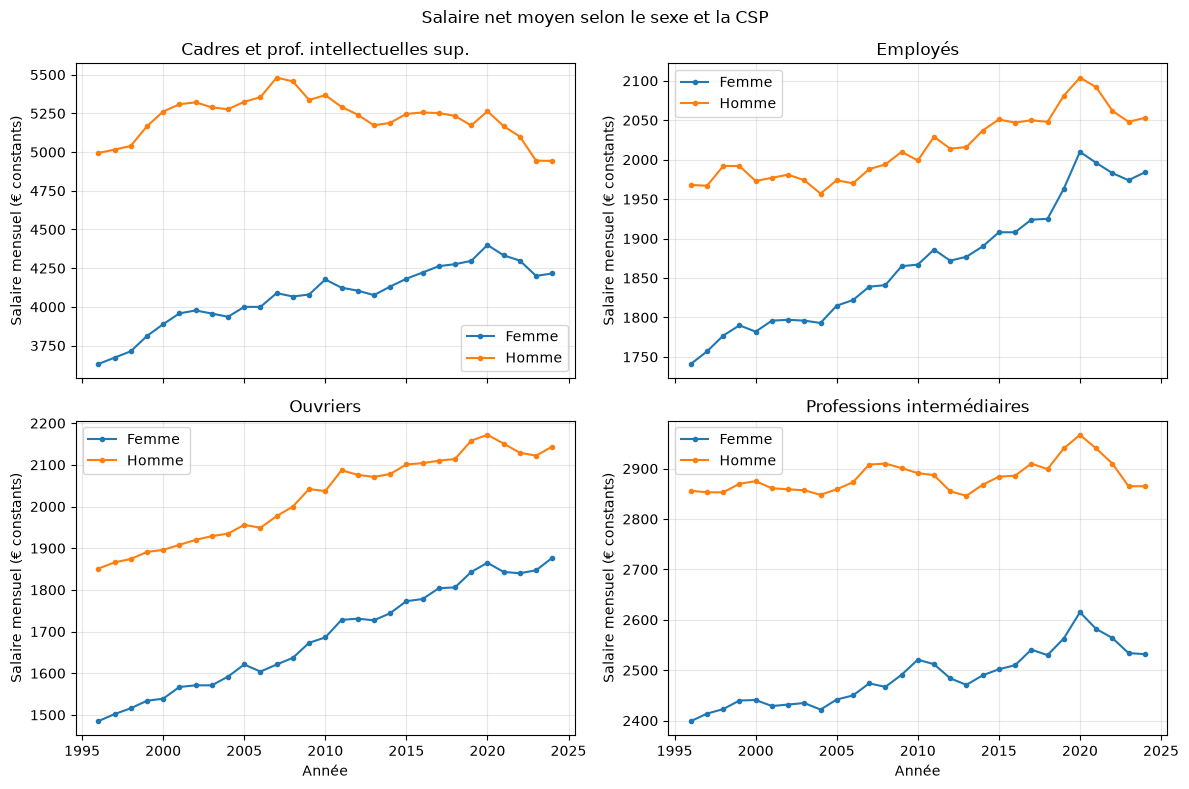

In [3]:
resume = (
    echantillon.groupby(['categorie_socio_prof', 'sexe'])['valeur']
    .agg(['count', 'mean', 'std', 'min', 'max'])
    .rename(columns={
        'count': 'Nombre d’années',
        'mean': 'Salaire moyen (€ constants)',
        'std': 'Écart-type entre années',
        'min': 'Minimum',
        'max': 'Maximum',
    })
)
display(resume.round(1))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for categorie, ax in zip(csp, axes.flat):
    donnees_csp = echantillon[echantillon['categorie_socio_prof'].eq(categorie)]
    for sexe in sexes:
        serie = donnees_csp[donnees_csp['sexe'].eq(sexe)].sort_values('annee')
        ax.plot(serie['annee'], serie['valeur'], marker='.', label=sexe)
    ax.set_title(categorie)
    ax.set_ylabel('Salaire mensuel (€ constants)')
    ax.grid(alpha=0.3)
    ax.legend()
for ax in axes[-1, :]:
    ax.set_xlabel('Année')
fig.suptitle('Salaire net moyen selon le sexe et la CSP')
fig.tight_layout()
plt.show()

## 4. Régression linéaire avec effets fixes d’année

Le modèle estimé est :

$$Salaire_{t,s,c} = \alpha + \beta_F Femme_s + \beta_c CSP_c + \delta_c(Femme_s \times CSP_c) + \lambda_t + \varepsilon_{t,s,c}$$

La CSP de référence est **Ouvriers** et le sexe de référence est **Homme**. Les erreurs-types sont regroupées par année, car les observations d’une même année partagent des conditions économiques communes. Les effets fixes d’année absorbent les différences de niveau propres à chaque année.

Pour chaque coefficient, le test de significativité vérifie l’hypothèse nulle $H_0 : \beta=0$. Une p-value inférieure à 0,05 est considérée comme statistiquement significative au seuil de 5 %. Une p-value plus élevée signifie qu’on ne rejette pas cette hypothèse au seuil retenu ; ce n’est pas une preuve que l’effet est exactement nul. Les tests sont approximatifs et doivent être interprétés prudemment, notamment parce qu’il y a 29 années regroupées.

In [4]:
formule = (
    "valeur ~ femme * C(categorie_socio_prof, Treatment(reference='Ouvriers')) "
    "+ C(annee)"
)
modele = smf.ols(formula=formule, data=echantillon).fit(
    cov_type='cluster',
    cov_kwds={'groups': echantillon['annee'], 'use_correction': True},
)
print(f'Formule : {formule}')
print(f"Observations : {int(modele.nobs)} ; années regroupées : {echantillon['annee'].nunique()}")
print(f"R² : {modele.rsquared:.3f} ; R² ajusté : {modele.rsquared_adj:.3f}")

Formule : valeur ~ femme * C(categorie_socio_prof, Treatment(reference='Ouvriers')) + C(annee)
Observations : 232 ; années regroupées : 29
R² : 0.996 ; R² ajusté : 0.995


## 5. Résultats et interprétation des coefficients

Le tableau ci-dessous met en avant les coefficients correspondant au sexe, à la CSP et à leur interaction. Les indicatrices d’année sont omises de ce tableau synthétique, mais restent incluses dans l’estimation.

In [5]:
termes = modele.params.index
masque_interet = (
    (termes == 'femme')
    | termes.str.startswith('C(categorie_socio_prof')
    | termes.str.startswith('femme:C(categorie_socio_prof')
)
intervalle = modele.conf_int()
table_coefficients = pd.DataFrame({
    'Coefficient (€)': modele.params[masque_interet],
    'IC 95 % bas (€)': intervalle.loc[masque_interet, 0],
    'IC 95 % haut (€)': intervalle.loc[masque_interet, 1],
    'Erreur-type cluster année (€)': modele.bse[masque_interet],
    'p-value': modele.pvalues[masque_interet],
})
table_coefficients['Significatif à 5 %'] = np.where(
    table_coefficients['p-value'] < 0.05, 'Oui', 'Non'
)
table_coefficients_affichage = table_coefficients.copy()
table_coefficients_affichage['p-value'] = table_coefficients_affichage['p-value'].map(formater_p_value)
display(table_coefficients_affichage.round(3))

print('Interprétation des coefficients (en euros mensuels constants) :')
for terme, ligne in table_coefficients.iterrows():
    coefficient = ligne['Coefficient (€)']
    p_value = ligne['p-value']
    decision = (
        'association statistiquement significative au seuil de 5 %'
        if p_value < 0.05
        else 'association non significative au seuil de 5 %'
    )
    if terme == 'femme':
        lecture = 'écart Femme–Homme chez les ouvriers'
    elif terme.startswith('femme:C(categorie_socio_prof'):
        categorie = terme.rsplit('[T.', 1)[-1].rstrip(']')
        lecture = f'différence de l’écart Femme–Homme entre {categorie} et les ouvriers'
    else:
        categorie = terme.rsplit('[T.', 1)[-1].rstrip(']')
        lecture = f'écart de salaire entre {categorie} et les ouvriers chez les hommes'
    print(f'- {lecture} : {coefficient:+.0f} € ; {decision} (p {formater_p_value(p_value)}).')

def test_conjoint(resultat, termes_testes):
    if not termes_testes:
        raise ValueError('La liste des coefficients à tester ne peut pas être vide.')
    matrice = np.zeros((len(termes_testes), len(resultat.params)))
    for ligne, terme in enumerate(termes_testes):
        matrice[ligne, resultat.params.index.get_loc(terme)] = 1
    return resultat.wald_test(matrice, use_f=True, scalar=True)

termes_csp = [
    terme for terme in modele.params.index
    if terme.startswith('C(categorie_socio_prof')
]
test_csp = test_conjoint(modele, termes_csp)
p_csp = float(np.asarray(test_csp.pvalue).reshape(-1)[0])
print(
    '\nTest conjoint des CSP chez les hommes '
    '(H₀ : les écarts avec les ouvriers sont tous nuls) : '
    f"F = {float(np.asarray(test_csp.statistic).reshape(-1)[0]):.2f}, p {formater_p_value(p_csp)}. "
    + ('Au moins une CSP diffère significativement des ouvriers au seuil de 5 %.'
       if p_csp < 0.05 else
       'On ne détecte pas de différence globale significative entre CSP au seuil de 5 %.')
)

interactions = [
    terme for terme in modele.params.index
    if terme.startswith('femme:C(categorie_socio_prof')
]
if not interactions:
    raise ValueError('Aucun coefficient d’interaction sexe-CSP trouvé.')
test_interactions = np.zeros((len(interactions), len(modele.params)))
for ligne, terme in enumerate(interactions):
    test_interactions[ligne, modele.params.index.get_loc(terme)] = 1
test_global_interactions = modele.wald_test(
    test_interactions, use_f=True, scalar=True
)
p_global = float(np.asarray(test_global_interactions.pvalue).reshape(-1)[0])
print(
    '\nTest conjoint des interactions (H₀ : tous les écarts supplémentaires '
    f'par CSP sont nuls) : F = {float(np.asarray(test_global_interactions.statistic).reshape(-1)[0]):.2f}, '
    f"p {formater_p_value(p_global)}. "
    + ('Les écarts femmes-hommes varient significativement selon la CSP au seuil de 5 %.'
       if p_global < 0.05 else
       'On ne détecte pas de variation significative des écarts femmes-hommes selon la CSP au seuil de 5 %.')
)

,Coefficient (€),IC 95 % bas (€),IC 95 % haut (€),Erreur-type cluster année (€),p-value,Significatif à 5 %
"C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Cadres et prof. intellectuelles sup.]",3200.966,3130.457,3271.474,35.974,"< 0,001",Oui
"C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Employés]",-6.897,-33.280,19.487,13.461,"0,608",Non
"C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Professions intermédiaires]",860.276,825.765,894.787,17.608,"< 0,001",Oui
femme,-335.276,-346.242,-324.309,5.595,"< 0,001",Oui
"femme:C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Cadres et prof. intellectuelles sup.]",-816.276,-893.966,-738.586,39.639,"< 0,001",Oui
"femme:C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Employés]",188.034,178.781,197.288,4.721,"< 0,001",Oui
"femme:C(categorie_socio_prof, Treatment(reference='Ouvriers'))[T.Professions intermédiaires]",-60.793,-68.938,-52.648,4.156,"< 0,001",Oui


Interprétation des coefficients (en euros mensuels constants) :
- écart de salaire entre Cadres et prof. intellectuelles sup. et les ouvriers chez les hommes : +3201 € ; association statistiquement significative au seuil de 5 % (p < 0,001).
- écart de salaire entre Employés et les ouvriers chez les hommes : -7 € ; association non significative au seuil de 5 % (p 0,608).
- écart de salaire entre Professions intermédiaires et les ouvriers chez les hommes : +860 € ; association statistiquement significative au seuil de 5 % (p < 0,001).
- écart Femme–Homme chez les ouvriers : -335 € ; association statistiquement significative au seuil de 5 % (p < 0,001).
- différence de l’écart Femme–Homme entre Cadres et prof. intellectuelles sup. et les ouvriers : -816 € ; association statistiquement significative au seuil de 5 % (p < 0,001).
- différence de l’écart Femme–Homme entre Employés et les ouvriers : +188 € ; association statistiquement significative au seuil de 5 % (p < 0,001).
- différence de

## 6. Écart Femme–Homme estimé dans chaque CSP

Pour chaque CSP, on calcule le contraste linéaire correspondant à l’écart Femme–Homme. Les intervalles de confiance utilisent toute la matrice de covariance (y compris les covariances entre coefficients), plutôt qu’une simple addition des erreurs-types.

In [6]:
nom_csp = 'C(categorie_socio_prof, Treatment(reference='
nom_effet_femme = 'femme'
ecarts = []
for categorie in csp:
    contraste = np.zeros(len(modele.params))
    contraste[modele.params.index.get_loc(nom_effet_femme)] = 1
    if categorie != 'Ouvriers':
        nom_interaction = (
            f"femme:{nom_csp}'Ouvriers'))[T.{categorie}]"
        )
        if nom_interaction not in modele.params.index:
            raise KeyError(f'Coefficient d’interaction introuvable : {nom_interaction}')
        contraste[modele.params.index.get_loc(nom_interaction)] = 1

    test = modele.t_test(contraste)
    borne_inf, borne_sup = np.asarray(test.conf_int()).reshape(-1)
    ecarts.append({
        'CSP': categorie,
        'Écart Femme–Homme (€)': float(np.asarray(test.effect).reshape(-1)[0]),
        'Borne inférieure 95 %': borne_inf,
        'Borne supérieure 95 %': borne_sup,
        'p-value': float(np.asarray(test.pvalue).reshape(-1)[0]),
    })

table_ecarts = pd.DataFrame(ecarts).set_index('CSP')
table_ecarts['Significatif à 5 %'] = np.where(
    table_ecarts['p-value'] < 0.05, 'Oui', 'Non'
)
table_ecarts_affichage = table_ecarts.copy()
table_ecarts_affichage['p-value'] = table_ecarts_affichage['p-value'].map(formater_p_value)
display(table_ecarts_affichage.round(2))
for categorie, ligne in table_ecarts.iterrows():
    direction = 'inférieur' if ligne['Écart Femme–Homme (€)'] < 0 else 'supérieur'
    if ligne['p-value'] < 0.05:
        print(
            f"- {categorie} : le salaire moyen estimé des femmes est "
            f"{direction} de {abs(ligne['Écart Femme–Homme (€)']):.0f} € à celui des hommes "
            f"(IC 95 % [{ligne['Borne inférieure 95 %']:.0f} ; "
            f"{ligne['Borne supérieure 95 %']:.0f}] € ; p {formater_p_value(ligne['p-value'])})."
        )
    else:
        print(
            f"- {categorie} : écart estimé de {ligne['Écart Femme–Homme (€)']:+.0f} €, "
            f"mais non significatif au seuil de 5 % (p {formater_p_value(ligne['p-value'])}) ; "
            'on ne peut pas conclure à un écart statistiquement différent de zéro.'
        )

,Écart Femme–Homme (€),Borne inférieure 95 %,Borne supérieure 95 %,p-value,Significatif à 5 %
CSP,,,,,
Cadres et prof. intellectuelles sup.,-1151.55,-1239.05,-1064.05,"< 0,001",Oui
Employés,-147.24,-163.54,-130.94,"< 0,001",Oui
Ouvriers,-335.28,-346.24,-324.31,"< 0,001",Oui
Professions intermédiaires,-396.07,-410.47,-381.67,"< 0,001",Oui


- Cadres et prof. intellectuelles sup. : le salaire moyen estimé des femmes est inférieur de 1152 € à celui des hommes (IC 95 % [-1239 ; -1064] € ; p < 0,001).
- Employés : le salaire moyen estimé des femmes est inférieur de 147 € à celui des hommes (IC 95 % [-164 ; -131] € ; p < 0,001).
- Ouvriers : le salaire moyen estimé des femmes est inférieur de 335 € à celui des hommes (IC 95 % [-346 ; -324] € ; p < 0,001).
- Professions intermédiaires : le salaire moyen estimé des femmes est inférieur de 396 € à celui des hommes (IC 95 % [-410 ; -382] € ; p < 0,001).


## 7. Bilan du modèle sexe-CSP et limites

- Le coefficient `femme` donne l’écart moyen Femme–Homme pour la CSP de référence (ouvriers), à année donnée.
- Les interactions indiquent comment cet écart varie selon les autres CSP ; les contrastes précédents donnent l’écart total estimé pour chaque CSP.
- Les salaires sont des moyennes agrégées : on ne contrôle pas ici les caractéristiques individuelles (ancienneté, métier précis, durée de travail individuelle, etc.).
- Une p-value significative indique que l’écart estimé est difficilement compatible avec un coefficient nul selon le modèle ; elle ne mesure ni l’importance pratique ni la probabilité que l’hypothèse nulle soit vraie.
- Le regroupement des erreurs-types par année tient compte d’une dépendance possible entre observations de la même année, mais le nombre de groupes (29 années) reste modeste.
- Les tableaux disponibles ne détaillent pas simultanément l’âge, la CSP et le secteur. Les analyses suivantes étudient séparément les tendances temporelles, les CSP et les quantiles ; elles ne décrivent pas des profils croisés.
- Ces résultats agrégés sont descriptifs et associatifs. Ils ne constituent pas une estimation causale d’une pénalité salariale individuelle ni une preuve isolée de discrimination.

## 8. Modèle complémentaire : âge et sexe

Les données disponibles pour étudier l’âge détaillent six tranches d’âge, mais indiquent la CSP « Ensemble ». Ce modèle estime donc les écarts liés à l’âge et au sexe **sans contrôler la CSP**. La tranche **31 à 40 ans** sert de référence. Les interactions âge-sexe permettent de vérifier si l’écart femmes-hommes varie selon l’âge.

In [7]:
echantillon_age = prive.loc[
    prive['indicateur'].eq(SALAIRE)
    & prive['centile_salaire'].eq('Ensemble')
    & prive['geo'].eq('F')
    & prive['secteur_activite'].eq('Ensemble des secteurs')
    & prive['tranche_age'].ne('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
    & prive['sexe'].isin(['Femme', 'Homme'])
    & prive['categorie_socio_prof'].eq('Ensemble'),
    ['annee', 'sexe', 'tranche_age', 'valeur'],
].copy()
echantillon_age['annee'] = pd.to_numeric(echantillon_age['annee'], errors='coerce')
echantillon_age['valeur'] = pd.to_numeric(echantillon_age['valeur'], errors='coerce')
if echantillon_age[['annee', 'valeur']].isna().any().any():
    raise ValueError('Des années ou des salaires manquent dans les données détaillées par âge.')
echantillon_age['annee'] = echantillon_age['annee'].astype(int)
echantillon_age['femme'] = echantillon_age['sexe'].eq('Femme').astype(int)

ages = sorted(echantillon_age['tranche_age'].unique())
annees_age = sorted(echantillon_age['annee'].unique())
cles_age = ['annee', 'sexe', 'tranche_age']
if echantillon_age.duplicated(cles_age).any():
    raise ValueError(f'Plusieurs observations pour les mêmes clés : {cles_age}')
attendues_age = pd.MultiIndex.from_product(
    [annees_age, sexes, ages], names=cles_age
)
observees_age = pd.MultiIndex.from_frame(echantillon_age[cles_age])
manquantes_age = attendues_age.difference(observees_age)
if len(manquantes_age):
    raise ValueError(f'Panel âge-sexe incomplet : {len(manquantes_age)} combinaisons manquent.')
print(
    f"Échantillon âge-sexe : {len(echantillon_age)} observations, "
    f"{len(ages)} tranches d’âge, de {min(annees_age)} à {max(annees_age)}."
)
display(
    echantillon_age.groupby(['tranche_age', 'sexe'])['valeur']
    .agg(['count', 'mean', 'std']).round(1)
)

Échantillon âge-sexe : 348 observations, 6 tranches d’âge, de 1996 à 2024.


count    mean    std
tranche_age     sexe                       
De 26 à 30 ans  Femme     29  2097.1  113.3
                Homme     29  2299.7   88.3
De 31 à 40 ans  Femme     29  2362.0  139.0
                Homme     29  2762.9   68.2
De 41 à 50 ans  Femme     29  2499.5  184.4
                Homme     29  3181.4   84.8
De 51 à 60 ans  Femme     29  2579.3  130.1
                Homme     29  3507.9   37.7
Moins de 26 ans Femme     29  1644.3   46.9
                Homme     29  1700.6   60.2
Plus de 60 ans  Femme     29  2757.3  225.2
                Homme     29  4382.9  350.4

Le modèle utilise les tranches d’âge comme variables catégorielles plutôt que d’attribuer un âge numérique arbitraire à chaque tranche. Le coefficient `femme` compare femmes et hommes de 31–40 ans ; les autres coefficients d’âge comparent les hommes à ceux de 31–40 ans ; les interactions mesurent les différences entre écarts femmes-hommes.

In [9]:
formule_age = (
    "valeur ~ femme * C(tranche_age, Treatment(reference='De 31 à 40 ans')) "
    "+ C(annee)"
)
modele_age = smf.ols(formula=formule_age, data=echantillon_age).fit(
    cov_type='cluster',
    cov_kwds={'groups': echantillon_age['annee'], 'use_correction': True},
)
print(f'Formule : {formule_age}')
print(
    f"Observations : {int(modele_age.nobs)} ; années regroupées : "
    f"{echantillon_age['annee'].nunique()} ; R² : {modele_age.rsquared:.3f}."
)

Formule : valeur ~ femme * C(tranche_age, Treatment(reference='De 31 à 40 ans')) + C(annee)
Observations : 348 ; années regroupées : 29 ; R² : 0.976.


In [10]:
termes_age = modele_age.params.index
masque_age = (
    (termes_age == 'femme')
    | termes_age.str.startswith('C(tranche_age')
    | termes_age.str.startswith('femme:C(tranche_age')
)
intervalle_age = modele_age.conf_int()
table_age = pd.DataFrame({
    'Coefficient (€)': modele_age.params[masque_age],
    'IC 95 % bas (€)': intervalle_age.loc[masque_age, 0],
    'IC 95 % haut (€)': intervalle_age.loc[masque_age, 1],
    'p-value': modele_age.pvalues[masque_age],
})
table_age['Significatif à 5 %'] = np.where(table_age['p-value'] < 0.05, 'Oui', 'Non')
table_age_affichage = table_age.copy()
table_age_affichage['p-value'] = table_age_affichage['p-value'].map(formater_p_value)
display(table_age_affichage.round(3))
print('Interprétation des coefficients (en euros mensuels constants) :')
for terme, ligne in table_age.iterrows():
    coefficient = ligne['Coefficient (€)']
    decision = (
        'significatif au seuil de 5 %'
        if ligne['p-value'] < 0.05
        else 'non significatif au seuil de 5 %'
    )
    if terme == 'femme':
        lecture = 'écart Femme–Homme chez les 31–40 ans'
    elif terme.startswith('femme:C(tranche_age'):
        age = terme.rsplit('[T.', 1)[-1].rstrip(']')
        lecture = f'différence de l’écart Femme–Homme entre {age} et les 31–40 ans'
    else:
        age = terme.rsplit('[T.', 1)[-1].rstrip(']')
        lecture = f'écart entre les hommes de {age} et ceux de 31–40 ans'
    print(f"- {lecture} : {coefficient:+.0f} € ; {decision} (p {formater_p_value(ligne['p-value'])}).")

termes_age_principaux = [
    terme for terme in modele_age.params.index
    if terme.startswith('C(tranche_age')
]
test_age_principal = test_conjoint(modele_age, termes_age_principaux)
p_age_principal = float(np.asarray(test_age_principal.pvalue).reshape(-1)[0])
print(
    '\nTest conjoint des tranches d’âge chez les hommes '
    '(H₀ : les écarts avec les 31–40 ans sont tous nuls) : '
    f"F = {float(np.asarray(test_age_principal.statistic).reshape(-1)[0]):.2f}, "
    f"p {formater_p_value(p_age_principal)}. "
    + ('Au moins une tranche d’âge diffère significativement des 31–40 ans au seuil de 5 %.'
       if p_age_principal < 0.05 else
       'On ne détecte pas de différence globale significative entre âges au seuil de 5 %.')
)

interactions_age = [
    terme for terme in modele_age.params.index
    if terme.startswith('femme:C(tranche_age')
]
test_interactions_age = test_conjoint(modele_age, interactions_age)
p_interactions_age = float(np.asarray(test_interactions_age.pvalue).reshape(-1)[0])
print(
    '\nTest conjoint des interactions âge-sexe '
    '(H₀ : l’écart femmes-hommes ne varie pas selon l’âge) : '
    f"F = {float(np.asarray(test_interactions_age.statistic).reshape(-1)[0]):.2f}, "
    f"p {formater_p_value(p_interactions_age)}. "
    + ('Les différences d’écarts selon l’âge sont significatives au seuil de 5 %.'
       if p_interactions_age < 0.05 else
       'On ne détecte pas de différence significative des écarts selon l’âge au seuil de 5 %.')
)

ecarts_age = []
for age in ages:
    contraste = np.zeros(len(modele_age.params))
    contraste[modele_age.params.index.get_loc('femme')] = 1
    if age != 'De 31 à 40 ans':
        correspondances = [
            terme for terme in interactions_age if terme.endswith(f'[T.{age}]')
        ]
        if len(correspondances) != 1:
            raise KeyError(f'Interaction âge-sexe introuvable ou ambiguë pour : {age}')
        contraste[modele_age.params.index.get_loc(correspondances[0])] = 1
    test = modele_age.t_test(contraste)
    borne_inf, borne_sup = np.asarray(test.conf_int()).reshape(-1)
    ecarts_age.append({
        'Tranche d’âge': age,
        'Écart Femme–Homme (€)': float(np.asarray(test.effect).reshape(-1)[0]),
        'IC 95 % bas (€)': borne_inf,
        'IC 95 % haut (€)': borne_sup,
        'p-value': float(np.asarray(test.pvalue).reshape(-1)[0]),
    })
table_ecarts_age = pd.DataFrame(ecarts_age).set_index('Tranche d’âge')
table_ecarts_age['Significatif à 5 %'] = np.where(
    table_ecarts_age['p-value'] < 0.05, 'Oui', 'Non'
)
table_ecarts_age_affichage = table_ecarts_age.copy()
table_ecarts_age_affichage['p-value'] = table_ecarts_age_affichage['p-value'].map(formater_p_value)
display(table_ecarts_age_affichage.round(2))
for age, ligne in table_ecarts_age.iterrows():
    decision = (
        'écart statistiquement significatif au seuil de 5 %'
        if ligne['p-value'] < 0.05
        else 'écart non significatif au seuil de 5 %'
    )
    print(
        f"- {age} : écart estimé Femme–Homme de "
        f"{ligne['Écart Femme–Homme (€)']:+.0f} € ({decision}, "
        f"p {formater_p_value(ligne['p-value'])})."
    )

,Coefficient (€),IC 95 % bas (€),IC 95 % haut (€),p-value,Significatif à 5 %
"C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 26 à 30 ans]",-463.207,-475.099,-451.315,"< 0,001",Oui
"C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 41 à 50 ans]",418.517,401.072,435.962,"< 0,001",Oui
"C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 51 à 60 ans]",745.000,720.251,769.749,"< 0,001",Oui
"C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.Moins de 26 ans]",-1062.345,-1076.571,-1048.118,"< 0,001",Oui
"C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.Plus de 60 ans]",1619.966,1492.949,1746.982,"< 0,001",Oui
femme,-400.862,-435.157,-366.567,"< 0,001",Oui
"femme:C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 26 à 30 ans]",198.241,176.573,219.910,"< 0,001",Oui
"femme:C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 41 à 50 ans]",-281.034,-294.442,-267.627,"< 0,001",Oui
"femme:C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.De 51 à 60 ans]",-527.690,-545.367,-510.012,"< 0,001",Oui
"femme:C(tranche_age, Treatment(reference='De 31 à 40 ans'))[T.Moins de 26 ans]",344.586,310.233,378.939,"< 0,001",Oui


Interprétation des coefficients (en euros mensuels constants) :
- écart entre les hommes de De 26 à 30 ans et ceux de 31–40 ans : -463 € ; significatif au seuil de 5 % (p < 0,001).
- écart entre les hommes de De 41 à 50 ans et ceux de 31–40 ans : +419 € ; significatif au seuil de 5 % (p < 0,001).
- écart entre les hommes de De 51 à 60 ans et ceux de 31–40 ans : +745 € ; significatif au seuil de 5 % (p < 0,001).
- écart entre les hommes de Moins de 26 ans et ceux de 31–40 ans : -1062 € ; significatif au seuil de 5 % (p < 0,001).
- écart entre les hommes de Plus de 60 ans et ceux de 31–40 ans : +1620 € ; significatif au seuil de 5 % (p < 0,001).
- écart Femme–Homme chez les 31–40 ans : -401 € ; significatif au seuil de 5 % (p < 0,001).
- différence de l’écart Femme–Homme entre De 26 à 30 ans et les 31–40 ans : +198 € ; significatif au seuil de 5 % (p < 0,001).
- différence de l’écart Femme–Homme entre De 41 à 50 ans et les 31–40 ans : -281 € ; significatif au seuil de 5 % (p < 0,001).
- 

,Écart Femme–Homme (€),IC 95 % bas (€),IC 95 % haut (€),p-value,Significatif à 5 %
Tranche d’âge,,,,,
De 26 à 30 ans,-202.62,-217.39,-187.85,"< 0,001",Oui
De 31 à 40 ans,-400.86,-435.16,-366.57,"< 0,001",Oui
De 41 à 50 ans,-681.90,-725.59,-638.20,"< 0,001",Oui
De 51 à 60 ans,-928.55,-977.76,-879.35,"< 0,001",Oui
Moins de 26 ans,-56.28,-64.05,-48.50,"< 0,001",Oui
Plus de 60 ans,-1625.52,-1759.82,-1491.21,"< 0,001",Oui


- De 26 à 30 ans : écart estimé Femme–Homme de -203 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).
- De 31 à 40 ans : écart estimé Femme–Homme de -401 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).
- De 41 à 50 ans : écart estimé Femme–Homme de -682 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).
- De 51 à 60 ans : écart estimé Femme–Homme de -929 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).
- Moins de 26 ans : écart estimé Femme–Homme de -56 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).
- Plus de 60 ans : écart estimé Femme–Homme de -1626 € (écart statistiquement significatif au seuil de 5 %, p < 0,001).


## 9. Régression n° 1 – L’évolution de l’écart salarial dans le temps

La spécification compare les salaires des femmes et des hommes année par année :

$$\ln(Salaire_{s,t}) = \alpha + \beta_1 Femme_s + \beta_2 Trend_t + \beta_3(Femme_s \times Trend_t) + \varepsilon_{s,t}$$

`Trend` vaut 0 en 1996, 1 en 1997, etc. Le coefficient central est $\beta_3$ : positif, il indique que le rapport salarial femmes-hommes augmente au fil du temps ; négatif, qu’il diminue. Il s’agit d’une tendance différentielle, pas de l’effet causal d’une politique.

**Limite de la source disponible :** le fichier du projet fournit le salaire net moyen **mensuel** en euros constants, et non le salaire annuel moyen EQTP du tableau EQTP02. La régression utilise donc cette série mensuelle (l’interprétation du coefficient en logarithme reste en variation relative). Le panel retenu couvre 1996–2024. L’écart annuel logarithmique permet d’estimer la pente différentielle avec une erreur-type Newey–West, robuste à l’autocorrélation d’ordre 1.

,β₃ : Femme × Trend (log/an),IC 95 % bas,IC 95 % haut,Variation relative annuelle (%),p-value
0,0.0038,0.0032,0.0044,0.3808,"< 0,001"


Observations : 58 ; années : 29 (1996–2024) ; erreurs-types Newey–West, 1 retard.
La tendance estimée indique une hausse du rapport salarial femmes-hommes.


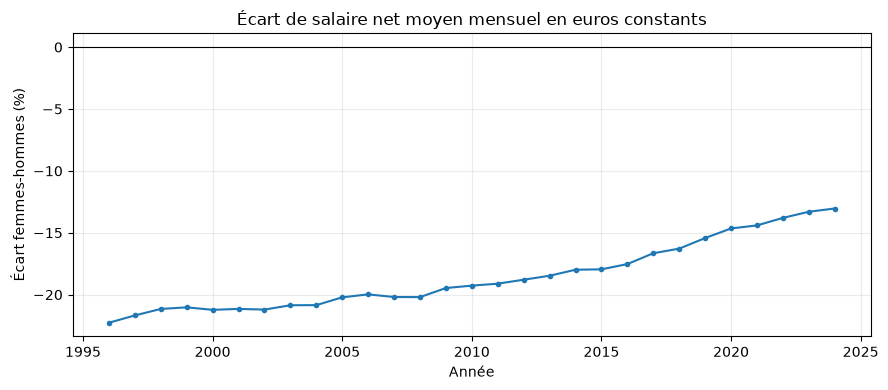

,β₃ (log/an),IC 95 % bas,IC 95 % haut,p-value
Période,,,,
1996–2024,0.0038,0.0032,0.0044,"< 0,001"
2000–2024,0.0043,0.0037,0.0049,"< 0,001"
2010–2024,0.0058,0.0053,0.0063,"< 0,001"


In [10]:
echantillon_tendance = prive.loc[
    prive['indicateur'].eq(SALAIRE)
    & prive['centile_salaire'].eq('Ensemble')
    & prive['geo'].eq('F')
    & prive['secteur_activite'].eq('Ensemble des secteurs')
    & prive['tranche_age'].eq('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
    & prive['categorie_socio_prof'].eq('Ensemble')
    & prive['sexe'].isin(['Femme', 'Homme']),
    ['annee', 'sexe', 'valeur'],
].copy()
echantillon_tendance['annee'] = pd.to_numeric(
    echantillon_tendance['annee'], errors='coerce'
)
echantillon_tendance['valeur'] = pd.to_numeric(
    echantillon_tendance['valeur'], errors='coerce'
)
if echantillon_tendance[['annee', 'valeur']].isna().any().any():
    raise ValueError('Des années ou des salaires manquent dans la série temporelle.')
echantillon_tendance['annee'] = echantillon_tendance['annee'].astype(int)
if (echantillon_tendance['valeur'] <= 0).any():
    raise ValueError('Le logarithme du salaire exige des valeurs strictement positives.')

cles_tendance = ['annee', 'sexe']
if echantillon_tendance.duplicated(cles_tendance).any():
    raise ValueError(f'Plusieurs observations pour les mêmes clés : {cles_tendance}')
salaire_par_sexe = echantillon_tendance.pivot(
    index='annee', columns='sexe', values='valeur'
).sort_index()
if salaire_par_sexe[['Femme', 'Homme']].isna().any().any():
    raise ValueError('La série temporelle ne contient pas les deux sexes pour chaque année.')
if 1996 not in salaire_par_sexe.index:
    raise ValueError('La série ne contient pas l’année de référence 1996.')

echantillon_tendance['femme'] = echantillon_tendance['sexe'].eq('Femme').astype(int)
echantillon_tendance['trend'] = echantillon_tendance['annee'] - 1996
modele_specification_tendance = smf.ols(
    'np.log(valeur) ~ femme * trend', data=echantillon_tendance
).fit()

ecarts_annuels = pd.DataFrame({
    'ecart_log': np.log(salaire_par_sexe['Femme'])
    - np.log(salaire_par_sexe['Homme']),
})
ecarts_annuels['trend'] = ecarts_annuels.index - 1996
modele_tendance = smf.ols(
    'ecart_log ~ trend', data=ecarts_annuels
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 1, 'use_correction': True},
)
if not np.isclose(
    modele_specification_tendance.params['femme:trend'],
    modele_tendance.params['trend'],
):
    raise ValueError('La pente de l’écart annuel ne correspond pas à l’interaction Femme × Trend.')

terme_tendance = 'trend'
intervalle_tendance = modele_tendance.conf_int().loc[terme_tendance]
beta3 = modele_tendance.params[terme_tendance]
table_tendance = pd.DataFrame([{
    'β₃ : Femme × Trend (log/an)': beta3,
    'IC 95 % bas': intervalle_tendance.iloc[0],
    'IC 95 % haut': intervalle_tendance.iloc[1],
    'Variation relative annuelle (%)': 100 * np.expm1(beta3),
    'p-value': modele_tendance.pvalues[terme_tendance],
}])
table_tendance_affichage = table_tendance.copy()
table_tendance_affichage['p-value'] = (
    table_tendance_affichage['p-value'].map(formater_p_value)
)
display(table_tendance_affichage.round(4))
print(
    f"Observations : {int(modele_specification_tendance.nobs)} ; "
    f"années : {len(ecarts_annuels)} ({min(ecarts_annuels.index)}–"
    f"{max(ecarts_annuels.index)}) ; erreurs-types Newey–West, 1 retard."
)
if beta3 > 0:
    print('La tendance estimée indique une hausse du rapport salarial femmes-hommes.')
elif beta3 < 0:
    print('La tendance estimée indique une baisse du rapport salarial femmes-hommes.')
else:
    print('La tendance estimée du rapport salarial femmes-hommes est nulle.')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    ecarts_annuels.index,
    100 * np.expm1(ecarts_annuels['ecart_log']),
    marker='o',
    markersize=3,
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(
    xlabel='Année',
    ylabel='Écart femmes-hommes (%)',
    title='Écart de salaire net moyen mensuel en euros constants',
)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

sensibilite_tendance = []
for debut in [1996, 2000, 2010]:
    sous_periode = ecarts_annuels.loc[ecarts_annuels.index >= debut].copy()
    resultat_periode = smf.ols(
        'ecart_log ~ trend', data=sous_periode
    ).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': 1, 'use_correction': True},
    )
    intervalle = resultat_periode.conf_int().loc['trend']
    sensibilite_tendance.append({
        'Période': f'{debut}–{sous_periode.index.max()}',
        'β₃ (log/an)': resultat_periode.params['trend'],
        'IC 95 % bas': intervalle.iloc[0],
        'IC 95 % haut': intervalle.iloc[1],
        'p-value': resultat_periode.pvalues['trend'],
    })
table_sensibilite_tendance = pd.DataFrame(sensibilite_tendance).set_index('Période')
table_sensibilite_tendance_affichage = table_sensibilite_tendance.copy()
table_sensibilite_tendance_affichage['p-value'] = (
    table_sensibilite_tendance_affichage['p-value'].map(formater_p_value)
)
display(table_sensibilite_tendance_affichage.round(4))

## 10. Régression n° 2 – Les écarts salariaux selon la CSP

Le modèle utilise les salaires nets moyens mensuels par sexe et CSP, en logarithme, avec effets fixes d’année. Les ouvriers et les hommes sont les catégories de référence :

$$\ln(Salaire_{s,c,t}) = \alpha + \beta_1 Femme_s + \beta_2 CSP_c + \beta_3(Femme_s \times CSP_c) + \lambda_t + \varepsilon_{s,c,t}$$

Les interactions mesurent si l’écart femmes-hommes diffère selon la CSP. Les erreurs-types sont regroupées par année. En complément, une seconde spécification ajoute `Femme × CSP × Trend` pour mesurer si l’évolution de l’écart varie selon la CSP. Les effets fixes absorbent la tendance commune : les tendances CSP sont donc exprimées relativement aux ouvriers, et le terme de tendance commun n’est pas estimé séparément. Cette extension reste descriptive.

In [11]:
echantillon_csp = echantillon.copy()
if (echantillon_csp['valeur'] <= 0).any():
    raise ValueError('Le logarithme du salaire exige des valeurs strictement positives.')

formule_csp = (
    "np.log(valeur) ~ femme * "
    "C(categorie_socio_prof, Treatment(reference='Ouvriers')) + C(annee)"
)
modele_csp = smf.ols(
    formula=formule_csp, data=echantillon_csp
).fit(
    cov_type='cluster',
    cov_kwds={'groups': echantillon_csp['annee'], 'use_correction': True},
)
if modele_csp.model.rank < len(modele_csp.params):
    raise ValueError('Le modèle sexe-CSP n’est pas de rang complet.')

termes_interactions_csp = [
    terme for terme in modele_csp.params.index
    if terme.startswith(
        "femme:C(categorie_socio_prof, Treatment(reference='Ouvriers'))"
    )
]
if len(termes_interactions_csp) != echantillon_csp['categorie_socio_prof'].nunique() - 1:
    raise ValueError('Les interactions sexe-CSP attendues ne sont pas toutes estimées.')

ecarts_csp = []
for categorie in ['Ouvriers', *sorted(
    c for c in echantillon_csp['categorie_socio_prof'].unique()
    if c != 'Ouvriers'
)]:
    contraste = np.zeros(len(modele_csp.params))
    contraste[modele_csp.params.index.get_loc('femme')] = 1
    if categorie != 'Ouvriers':
        terme = (
            "femme:C(categorie_socio_prof, Treatment(reference='Ouvriers'))"
            f"[T.{categorie}]"
        )
        if terme not in modele_csp.params.index:
            raise KeyError(f'Interaction sexe-CSP introuvable pour : {categorie}')
        contraste[modele_csp.params.index.get_loc(terme)] = 1
    test_ecart = modele_csp.t_test(contraste)
    effet = float(np.asarray(test_ecart.effect).reshape(-1)[0])
    intervalle = np.asarray(test_ecart.conf_int()).reshape(-1)
    ecarts_csp.append({
        'CSP': categorie,
        'Écart Femme–Homme (%)': 100 * np.expm1(effet),
        'IC 95 % bas (%)': 100 * np.expm1(intervalle[0]),
        'IC 95 % haut (%)': 100 * np.expm1(intervalle[1]),
        'p-value': float(np.asarray(test_ecart.pvalue).reshape(-1)[0]),
    })
table_ecarts_csp = pd.DataFrame(ecarts_csp).set_index('CSP')
table_ecarts_csp['Significatif à 5 %'] = np.where(
    table_ecarts_csp['p-value'] < 0.05, 'Oui', 'Non'
)
table_ecarts_csp_affichage = table_ecarts_csp.copy()
table_ecarts_csp_affichage['p-value'] = (
    table_ecarts_csp_affichage['p-value'].map(formater_p_value)
)
display(table_ecarts_csp_affichage.round(2))
print(
    f"Observations : {int(modele_csp.nobs)} ; années : "
    f"{echantillon_csp['annee'].nunique()} ; R² : {modele_csp.rsquared:.3f}."
)
test_interactions_csp = test_conjoint(modele_csp, termes_interactions_csp)
print(
    'Test conjoint des interactions Femme × CSP : '
    f"F = {float(np.asarray(test_interactions_csp.statistic).reshape(-1)[0]):.2f}, "
    f"p {formater_p_value(float(np.asarray(test_interactions_csp.pvalue).reshape(-1)[0]))}."
)

echantillon_csp_tendance = echantillon_csp.copy()
echantillon_csp_tendance['trend'] = echantillon_csp_tendance['annee'] - 1996
categories_csp_non_reference = sorted(
    categorie for categorie in echantillon_csp_tendance['categorie_socio_prof'].unique()
    if categorie != 'Ouvriers'
)
colonnes_tendance_csp = {}
for indice, categorie in enumerate(categories_csp_non_reference):
    colonne = f'trend_csp_{indice}'
    echantillon_csp_tendance[colonne] = (
        echantillon_csp_tendance['categorie_socio_prof'].eq(categorie).astype(int)
        * echantillon_csp_tendance['trend']
    )
    colonnes_tendance_csp[categorie] = colonne

termes_triples_csp = [
    f'femme:{colonne}' for colonne in colonnes_tendance_csp.values()
]
formule_csp_tendance = (
    "np.log(valeur) ~ femme * "
    "C(categorie_socio_prof, Treatment(reference='Ouvriers')) "
    "+ femme:trend + C(annee)"
    + ''.join(
        f' + {colonne} + femme:{colonne}'
        for colonne in colonnes_tendance_csp.values()
    )
)
modele_csp_tendance = smf.ols(
    formula=formule_csp_tendance, data=echantillon_csp_tendance
).fit(
    cov_type='cluster',
    cov_kwds={'groups': echantillon_csp_tendance['annee'], 'use_correction': True},
)
if modele_csp_tendance.model.rank < len(modele_csp_tendance.params):
    raise ValueError('Le modèle avec interaction triple n’est pas de rang complet.')

if any(terme not in modele_csp_tendance.params.index for terme in termes_triples_csp):
    raise ValueError('Les interactions triples Femme × CSP × Trend attendues sont absentes.')

pentes_ecart_csp = []
for categorie in ['Ouvriers', *sorted(
    c for c in echantillon_csp_tendance['categorie_socio_prof'].unique()
    if c != 'Ouvriers'
)]:
    contraste = np.zeros(len(modele_csp_tendance.params))
    contraste[modele_csp_tendance.params.index.get_loc('femme:trend')] = 1
    if categorie != 'Ouvriers':
        terme = f'femme:{colonnes_tendance_csp[categorie]}'
        contraste[modele_csp_tendance.params.index.get_loc(terme)] = 1
    test_pente = modele_csp_tendance.t_test(contraste)
    pente = float(np.asarray(test_pente.effect).reshape(-1)[0])
    intervalle = np.asarray(test_pente.conf_int()).reshape(-1)
    pentes_ecart_csp.append({
        'CSP': categorie,
        'Variation annuelle de l’écart (%)': 100 * np.expm1(pente),
        'IC 95 % bas (%)': 100 * np.expm1(intervalle[0]),
        'IC 95 % haut (%)': 100 * np.expm1(intervalle[1]),
        'p-value': float(np.asarray(test_pente.pvalue).reshape(-1)[0]),
    })
table_pentes_ecart_csp = pd.DataFrame(pentes_ecart_csp).set_index('CSP')
table_pentes_ecart_csp_affichage = table_pentes_ecart_csp.copy()
table_pentes_ecart_csp_affichage['p-value'] = (
    table_pentes_ecart_csp_affichage['p-value'].map(formater_p_value)
)
display(table_pentes_ecart_csp_affichage.round(3))
test_triples_csp = test_conjoint(modele_csp_tendance, termes_triples_csp)
print(
    'Test conjoint des interactions Femme × CSP × Trend '
    '(variation des tendances par rapport aux ouvriers) : '
    f"F = {float(np.asarray(test_triples_csp.statistic).reshape(-1)[0]):.2f}, "
    f"p {formater_p_value(float(np.asarray(test_triples_csp.pvalue).reshape(-1)[0]))}."
)

,Écart Femme–Homme (%),IC 95 % bas (%),IC 95 % haut (%),p-value,Significatif à 5 %
CSP,,,,,
Ouvriers,-16.69,-17.50,-15.88,"< 0,001",Oui
Cadres et prof. intellectuelles sup.,-22.11,-23.68,-20.51,"< 0,001",Oui
Employés,-7.36,-8.22,-6.51,"< 0,001",Oui
Professions intermédiaires,-13.76,-14.28,-13.23,"< 0,001",Oui


Observations : 232 ; années : 29 ; R² : 0.995.
Test conjoint des interactions Femme × CSP : F = 1413.57, p < 0,001.


,Variation annuelle de l’écart (%),IC 95 % bas (%),IC 95 % haut (%),p-value
CSP,,,,
Ouvriers,0.279,0.253,0.306,"< 0,001"
Cadres et prof. intellectuelles sup.,0.591,0.539,0.643,"< 0,001"
Employés,0.266,0.241,0.292,"< 0,001"
Professions intermédiaires,0.172,0.157,0.186,"< 0,001"


Test conjoint des interactions Femme × CSP × Trend (variation des tendances par rapport aux ouvriers) : F = 201.23, p < 0,001.


## 11. Régression n° 3 – Les écarts selon la position dans la distribution

Les données du projet contiennent les salaires moyens mensuels par sexe à sept positions de la distribution (D1, Q1, médiane, Q3, D9, P95 et P99). Elles permettent donc d’étudier si l’écart femmes-hommes est différent en bas et en haut de la distribution, sans utiliser le tableau EQTP08 lui-même.

Le modèle est :

$$\ln(Salaire_{s,q,t}) = \alpha + \beta_1 Femme_s + \beta_2 Quantile_q + \beta_3(Femme_s \times Quantile_q) + \lambda_t + \varepsilon_{s,q,t}$$

La médiane sert de référence. Les interactions indiquent comment l’écart de rémunération à chaque quantile diffère de l’écart à la médiane. Les erreurs-types sont regroupées par année ; les salaires sont des statistiques agrégées, et non des observations individuelles.

In [12]:
quantiles_ordonnes = [
    '10e centile (D1 - 10% gagnent moins)',
    '1er quartile (Q1 - 25% gagnent moins)',
    'Médiane (50% gagnent moins/plus)',
    '3e quartile (Q3 - 75% gagnent moins)',
    '90e centile (D9 - 10% gagnent plus)',
    '95e centile (Top 5%)',
    '99e centile (Top 1%)',
]
reference_quantile = 'Médiane (50% gagnent moins/plus)'
echantillon_quantiles = prive.loc[
    prive['indicateur'].eq(SALAIRE)
    & prive['centile_salaire'].isin(quantiles_ordonnes)
    & prive['geo'].eq('F')
    & prive['secteur_activite'].eq('Ensemble des secteurs')
    & prive['tranche_age'].eq('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
    & prive['categorie_socio_prof'].eq('Ensemble')
    & prive['sexe'].isin(['Femme', 'Homme']),
    ['annee', 'sexe', 'centile_salaire', 'valeur'],
].copy()
echantillon_quantiles['annee'] = pd.to_numeric(
    echantillon_quantiles['annee'], errors='coerce'
)
echantillon_quantiles['valeur'] = pd.to_numeric(
    echantillon_quantiles['valeur'], errors='coerce'
)
if echantillon_quantiles[['annee', 'valeur']].isna().any().any():
    raise ValueError('Des années ou des salaires manquent dans les données par quantile.')
echantillon_quantiles['annee'] = echantillon_quantiles['annee'].astype(int)
if (echantillon_quantiles['valeur'] <= 0).any():
    raise ValueError('Le logarithme du salaire exige des valeurs strictement positives.')

cles_quantiles = ['annee', 'sexe', 'centile_salaire']
if echantillon_quantiles.duplicated(cles_quantiles).any():
    raise ValueError(f'Plusieurs observations pour les mêmes clés : {cles_quantiles}')
annees_quantiles = sorted(echantillon_quantiles['annee'].unique())
attendues_quantiles = pd.MultiIndex.from_product(
    [annees_quantiles, ['Femme', 'Homme'], quantiles_ordonnes],
    names=cles_quantiles,
)
observees_quantiles = pd.MultiIndex.from_frame(echantillon_quantiles[cles_quantiles])
manquantes_quantiles = attendues_quantiles.difference(observees_quantiles)
if len(manquantes_quantiles):
    raise ValueError(
        f"Panel sexe-quantile incomplet : {len(manquantes_quantiles)} combinaisons manquent."
    )

formule_quantiles = (
    "np.log(valeur) ~ femme * "
    f"C(centile_salaire, Treatment(reference='{reference_quantile}')) + C(annee)"
)
echantillon_quantiles['femme'] = (
    echantillon_quantiles['sexe'].eq('Femme').astype(int)
)
modele_quantiles = smf.ols(
    formula=formule_quantiles, data=echantillon_quantiles
).fit(
    cov_type='cluster',
    cov_kwds={'groups': echantillon_quantiles['annee'], 'use_correction': True},
)
if modele_quantiles.model.rank < len(modele_quantiles.params):
    raise ValueError('Le modèle sexe-quantile n’est pas de rang complet.')

ecarts_quantiles = []
for quantile in quantiles_ordonnes:
    contraste = np.zeros(len(modele_quantiles.params))
    contraste[modele_quantiles.params.index.get_loc('femme')] = 1
    if quantile != reference_quantile:
        termes_quantile = [
            terme for terme in modele_quantiles.params.index
            if terme.startswith('femme:')
            and 'C(centile_salaire' in terme
            and terme.endswith(f'[T.{quantile}]')
        ]
        if len(termes_quantile) != 1:
            raise KeyError(f'Interaction sexe-quantile introuvable ou ambiguë : {quantile}')
        contraste[modele_quantiles.params.index.get_loc(termes_quantile[0])] = 1
    test_ecart = modele_quantiles.t_test(contraste)
    effet = float(np.asarray(test_ecart.effect).reshape(-1)[0])
    intervalle = np.asarray(test_ecart.conf_int()).reshape(-1)
    ecarts_quantiles.append({
        'Quantile': quantile,
        'Écart Femme–Homme (%)': 100 * np.expm1(effet),
        'IC 95 % bas (%)': 100 * np.expm1(intervalle[0]),
        'IC 95 % haut (%)': 100 * np.expm1(intervalle[1]),
        'p-value': float(np.asarray(test_ecart.pvalue).reshape(-1)[0]),
    })
table_ecarts_quantiles = pd.DataFrame(ecarts_quantiles).set_index('Quantile')
table_ecarts_quantiles['Significatif à 5 %'] = np.where(
    table_ecarts_quantiles['p-value'] < 0.05, 'Oui', 'Non'
)
table_ecarts_quantiles_affichage = table_ecarts_quantiles.copy()
table_ecarts_quantiles_affichage['p-value'] = (
    table_ecarts_quantiles_affichage['p-value'].map(formater_p_value)
)
display(table_ecarts_quantiles_affichage.round(2))

termes_interactions_quantiles = [
    terme for terme in modele_quantiles.params.index
    if terme.startswith('femme:') and 'C(centile_salaire' in terme
]
if len(termes_interactions_quantiles) != len(quantiles_ordonnes) - 1:
    raise ValueError('Les interactions sexe-quantile attendues ne sont pas toutes estimées.')
test_interactions_quantiles = test_conjoint(
    modele_quantiles, termes_interactions_quantiles
)
print(
    f"Observations : {int(modele_quantiles.nobs)} ; années : "
    f"{echantillon_quantiles['annee'].nunique()} ; R² : {modele_quantiles.rsquared:.3f}."
)
print(
    'Test conjoint des interactions Femme × Quantile '
    '(H₀ : l’écart femmes-hommes est identique à tous les quantiles) : '
    f"F = {float(np.asarray(test_interactions_quantiles.statistic).reshape(-1)[0]):.2f}, "
    f"p {formater_p_value(float(np.asarray(test_interactions_quantiles.pvalue).reshape(-1)[0]))}."
)

,Écart Femme–Homme (%),IC 95 % bas (%),IC 95 % haut (%),p-value,Significatif à 5 %
Quantile,,,,,
10e centile (D1 - 10% gagnent moins),-6.28,-7.11,-5.44,"< 0,001",Oui
1er quartile (Q1 - 25% gagnent moins),-9.61,-10.37,-8.84,"< 0,001",Oui
Médiane (50% gagnent moins/plus),-12.97,-13.72,-12.21,"< 0,001",Oui
3e quartile (Q3 - 75% gagnent moins),-15.99,-16.82,-15.14,"< 0,001",Oui
90e centile (D9 - 10% gagnent plus),-22.79,-24.32,-21.23,"< 0,001",Oui
95e centile (Top 5%),-27.16,-29.04,-25.22,"< 0,001",Oui
99e centile (Top 1%),-34.98,-36.65,-33.27,"< 0,001",Oui


Observations : 406 ; années : 29 ; R² : 0.999.
Test conjoint des interactions Femme × Quantile (H₀ : l’écart femmes-hommes est identique à tous les quantiles) : F = 3511.93, p < 0,001.


## 12. Conclusion d’ensemble

Les trois régressions examinent l’écart femmes-hommes sous des angles complémentaires : son évolution temporelle, ses différences selon la CSP et sa variation le long de la distribution des salaires. Les erreurs-types tiennent compte de la dépendance temporelle dans la première analyse (Newey–West) et regroupent les observations par année dans les modèles par CSP et quantile.

Les données du dépôt portent sur le salaire net moyen mensuel en euros constants ; elles ne sont pas les tableaux EQTP02 et EQTP08 et ne donnent pas directement le salaire annuel moyen EQTP. Les résultats restent des associations calculées sur des moyennes ou quantiles agrégés. Ils ne permettent ni d’isoler des trajectoires individuelles comparables, ni d’identifier l’effet causal d’une politique d’égalité ou une discrimination individuelle.